# Predicting Wind Near Irvine

AI SCI 290A

Now I try predicting tomorrow's wind. I make separate predictions for u and v. u describes wind going east or west, and v describes wind going north or south. Positive u points east and positive v points north. Both are in m/s.

The files give daily averages of these two parts of the wind. They do not give gusts or the average wind speed.

## 1. Load the wind data

In [1]:
import glob
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

DATA_DIR = "C:/Users/giorg/Desktop/290A/Project1_WeatherPrediction/data/data"

In [2]:
u_files = sorted(glob.glob(f"{DATA_DIR}/**/10m_u_component_of_wind*.nc", recursive=True))
v_files = sorted(glob.glob(f"{DATA_DIR}/**/10m_v_component_of_wind*.nc", recursive=True))

print("U wind files:", len(u_files))
print("V wind files:", len(v_files))

U wind files: 12
V wind files: 12


In [3]:
ds_u = xr.open_mfdataset(u_files, combine="by_coords")
ds_v = xr.open_mfdataset(v_files, combine="by_coords")

print("U units:", ds_u["u10"].attrs.get("units"))
print("V units:", ds_v["v10"].attrs.get("units"))

U units: m s**-1
V units: m s**-1


## 2. Select the point near Irvine

I use the same location as before. I check the actual coordinates and dates before putting the two components together.

In [4]:
u_irvine = ds_u["u10"].sel(latitude=33.75, longitude=-117.75, method="nearest")
v_irvine = ds_v["v10"].sel(latitude=33.75, longitude=-117.75, method="nearest")

print("U location:", float(u_irvine.latitude), float(u_irvine.longitude))
print("V location:", float(v_irvine.latitude), float(v_irvine.longitude))

u_series = u_irvine.to_series()
v_series = v_irvine.to_series()
print("Same dates:", u_series.index.equals(v_series.index))

U location: 33.75 -117.75
V location: 33.75 -117.75


Same dates: True


In [5]:
df_wind = pd.DataFrame({"today_u": u_series, "today_v": v_series})

print("Date range:", df_wind.index.min(), "to", df_wind.index.max())
print("Dates sorted:", df_wind.index.is_monotonic_increasing)
print("Dates unique:", df_wind.index.is_unique)
print("Missing values:")
print(df_wind.isna().sum())
expected_dates = pd.date_range(df_wind.index.min(), df_wind.index.max(), freq="D")
print("Missing dates:", expected_dates.difference(df_wind.index))
df_wind.head()

Date range: 2009-01-01 00:00:00 to 2010-12-31 00:00:00
Dates sorted: True
Dates unique: True
Missing values:
today_u    0
today_v    0
dtype: int64
Missing dates: DatetimeIndex([], dtype='datetime64[ns]', freq='D')


,today_u,today_v
valid_time,,
2009-01-01,-0.581250,0.012833
2009-01-02,-0.532312,0.843110
2009-01-03,-0.766132,1.317292
2009-01-04,-0.897218,-0.563737
2009-01-05,-0.796495,-0.120888


## 3. Look at wind over time

I plot January 2009 through June 2010. Negative values mean wind in the opposite direction, not missing data.

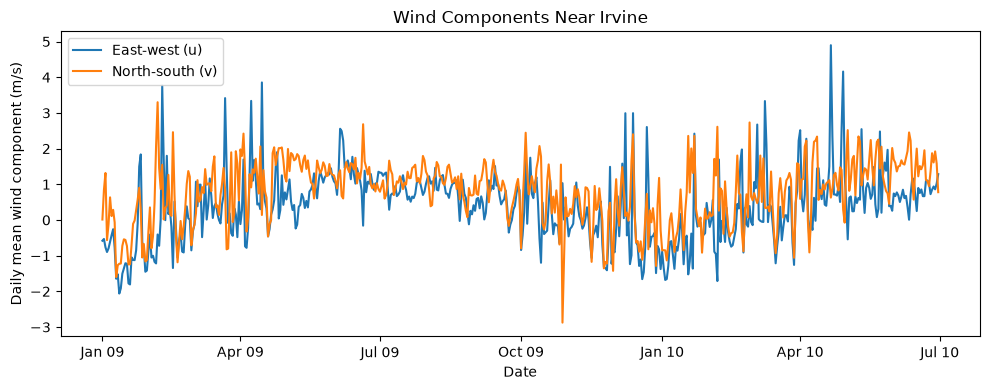

In [6]:
wind_plot = df_wind.loc[:"2010-06-30"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(wind_plot.index, wind_plot["today_u"], label="East-west (u)")
ax.plot(wind_plot.index, wind_plot["today_v"], label="North-south (v)")
ax.set_xlabel("Date")
ax.set_ylabel("Daily mean wind component (m/s)")
ax.set_title("Wind Components Near Irvine")
ax.legend()

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
fig.tight_layout()

## 4. Add tomorrow's wind

I put today's wind and tomorrow's actual wind on the same row. Today's values will be the inputs, and tomorrow's values will be the answers the models learn from. I remove the last row because it has no next day in the data.

In [7]:
# Match today's inputs with tomorrow's observations.
df_wind["tomorrow_u"] = df_wind["today_u"].shift(-1)
df_wind["tomorrow_v"] = df_wind["today_v"].shift(-1)
df_wind["target_date"] = df_wind.index + pd.Timedelta(days=1)

df_wind_model = df_wind.dropna(
    subset=["today_u", "today_v", "tomorrow_u", "tomorrow_v"]
).copy()

print("Rows for modeling:", len(df_wind_model))
df_wind_model.head()

Rows for modeling: 729


,today_u,today_v,tomorrow_u,tomorrow_v,target_date
valid_time,,,,,
2009-01-01,-0.581250,0.012833,-0.532312,0.843110,2009-01-02
2009-01-02,-0.532312,0.843110,-0.766132,1.317292,2009-01-03
2009-01-03,-0.766132,1.317292,-0.897218,-0.563737,2009-01-04
2009-01-04,-0.897218,-0.563737,-0.796495,-0.120888,2009-01-05
2009-01-05,-0.796495,-0.120888,-0.606314,0.634251,2009-01-06


## 5. Start with the first validation period

I use the same three rounds as before. The dates in this table are the days I want to predict.

| Round | Training dates | Validation dates |
| --- | --- | --- |
| 1 | 2009 | Jan-Feb 2010 |
| 2 | 2009-Feb 2010 | Mar-Apr 2010 |
| 3 | 2009-Apr 2010 | May-Jun 2010 |

I start with January-February. Each time I move to the next round, I add the earlier months to training. The July-December comparison is in notebook 06. I have already used that period in an earlier temperature test, so it is not completely new to the project.

In [8]:
train_1 = df_wind_model[df_wind_model["target_date"] < "2010-01-01"].copy()
val_1 = df_wind_model[
    (df_wind_model["target_date"] >= "2010-01-01") &
    (df_wind_model["target_date"] < "2010-03-01")
].copy()

print("Training rows:", len(train_1))
print("Validation rows:", len(val_1))

Training rows: 364
Validation rows: 59


## 6. Persistence baseline

My first guess is that tomorrow's u and v will equal today's. I check MAE and RMSE separately for each component. The units are m/s, so I cannot directly compare these scores with temperature errors in C.

In [9]:
val_1["u_persistence"] = val_1["today_u"]
val_1["v_persistence"] = val_1["today_v"]

u_errors = val_1["u_persistence"] - val_1["tomorrow_u"]
v_errors = val_1["v_persistence"] - val_1["tomorrow_v"]

baseline_results = pd.DataFrame({
    "Component": ["u", "v"],
    "MAE": [u_errors.abs().mean(), v_errors.abs().mean()],
    "RMSE": [(u_errors.pow(2).mean()) ** 0.5, (v_errors.pow(2).mean()) ** 0.5]
})
baseline_results.round(4)

,Component,MAE,RMSE
0,u,0.6702,1.0321
1,v,0.7236,0.9434


## 7. Try linear regression

I fit two linear regressions using today's u and v: one predicts tomorrow's u and the other predicts tomorrow's v. I train on 2009 and check January-February 2010.

In [10]:
from sklearn.linear_model import LinearRegression

wind_features = ["today_u", "today_v"]
X_train_1 = train_1[wind_features]
y_u_train_1 = train_1["tomorrow_u"]
y_v_train_1 = train_1["tomorrow_v"]

print("Input shape:", X_train_1.shape)

Input shape: (364, 2)


In [11]:
reg_u_1 = LinearRegression()
reg_u_1.fit(X_train_1, y_u_train_1)

reg_v_1 = LinearRegression()
reg_v_1.fit(X_train_1, y_v_train_1)

coefficients_1 = pd.DataFrame({
    "Predict tomorrow u": reg_u_1.coef_,
    "Predict tomorrow v": reg_v_1.coef_
}, index=wind_features)
print(coefficients_1)
print("U intercept:", reg_u_1.intercept_)
print("V intercept:", reg_v_1.intercept_)

         Predict tomorrow u  Predict tomorrow v
today_u            0.426472            0.080213
today_v            0.384894            0.599868
U intercept: -0.079382926
V intercept: 0.26477993


### Predict the validation days

I use the models trained on the earlier dates to predict January-February. Both the models and persistence use today's wind as the input.

In [12]:
X_val_1 = val_1[wind_features]
val_1["u_linear"] = reg_u_1.predict(X_val_1)
val_1["v_linear"] = reg_v_1.predict(X_val_1)

val_1[["target_date", "tomorrow_u", "u_linear", "tomorrow_v", "v_linear"]].head()

,target_date,tomorrow_u,u_linear,tomorrow_v,v_linear
valid_time,,,,,
2009-12-31,2010-01-01,-0.889013,-0.780195,-0.852325,-0.023564
2010-01-01,2010-01-02,-1.345368,-0.786577,-0.845762,-0.317813
2010-01-02,2010-01-03,-1.680735,-0.978673,-0.851386,-0.350481
2010-01-03,2010-01-04,-1.654990,-1.123863,-1.132694,-0.380756
2010-01-04,2010-01-05,-1.286786,-1.221157,-0.663049,-0.547439


### Compare the errors

I compare both models on the same 59 days. I keep u and v separate so I can see whether the model helps each component.

In [13]:
u_linear_errors_1 = val_1["u_linear"] - val_1["tomorrow_u"]
v_linear_errors_1 = val_1["v_linear"] - val_1["tomorrow_v"]

results_1 = pd.DataFrame({
    "Component": ["u", "u", "v", "v"],
    "Model": ["Persistence", "Linear regression", "Persistence", "Linear regression"],
    "MAE": [
        u_errors.abs().mean(), u_linear_errors_1.abs().mean(),
        v_errors.abs().mean(), v_linear_errors_1.abs().mean()
    ],
    "RMSE": [
        ((u_errors ** 2).mean()) ** 0.5,
        ((u_linear_errors_1 ** 2).mean()) ** 0.5,
        ((v_errors ** 2).mean()) ** 0.5,
        ((v_linear_errors_1 ** 2).mean()) ** 0.5
    ]
})
results_1.round(4)

,Component,Model,MAE,RMSE
0,u,Persistence,0.6702,1.0321
1,u,Linear regression,0.6165,0.8435
2,v,Persistence,0.7236,0.9434
3,v,Linear regression,0.6496,0.8341


### Look at the predictions

I make one plot for u and one for v. The date on each plot is the day I am predicting.

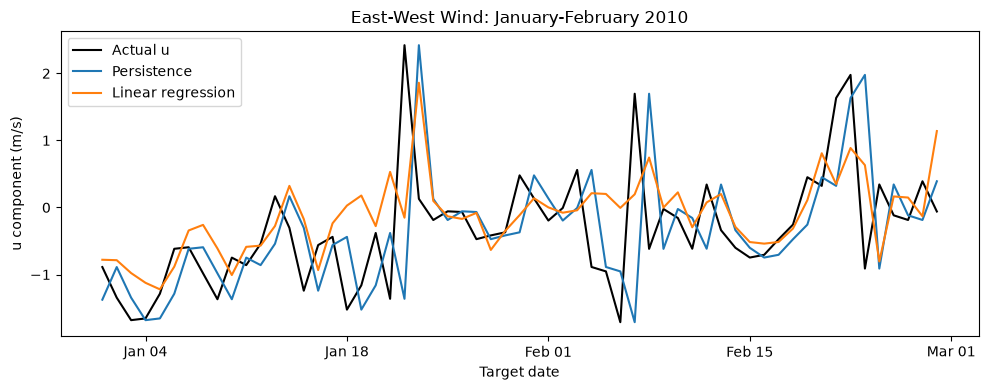

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(val_1["target_date"], val_1["tomorrow_u"], color="black", label="Actual u")
ax.plot(val_1["target_date"], val_1["u_persistence"], label="Persistence")
ax.plot(val_1["target_date"], val_1["u_linear"], label="Linear regression")
ax.set_xlabel("Target date")
ax.set_ylabel("u component (m/s)")
ax.set_title("East-West Wind: January-February 2010")
ax.legend()

ax.xaxis.set_major_locator(mdates.DayLocator(interval=14))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
fig.tight_layout()

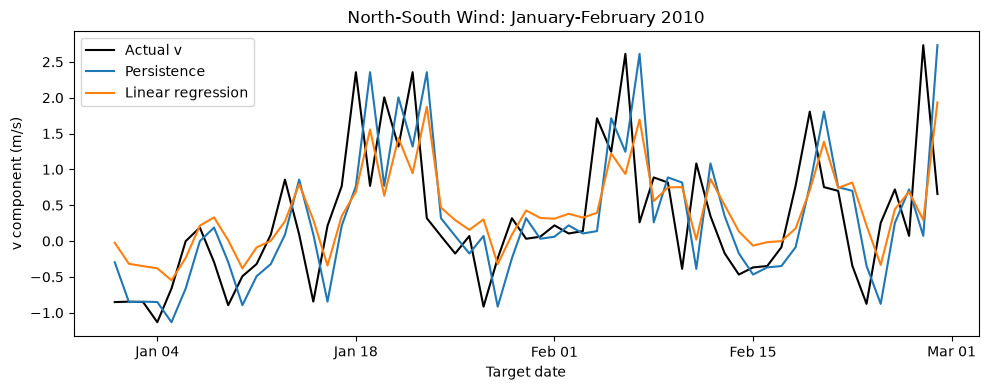

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(val_1["target_date"], val_1["tomorrow_v"], color="black", label="Actual v")
ax.plot(val_1["target_date"], val_1["v_persistence"], label="Persistence")
ax.plot(val_1["target_date"], val_1["v_linear"], label="Linear regression")
ax.set_xlabel("Target date")
ax.set_ylabel("v component (m/s)")
ax.set_title("North-South Wind: January-February 2010")
ax.legend()

ax.xaxis.set_major_locator(mdates.DayLocator(interval=14))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
fig.tight_layout()

## 8. Round 2: March-April 2010

I add the earlier months to training and check March-April, using the same inputs.

In [16]:
train_2 = df_wind_model[df_wind_model["target_date"] < "2010-03-01"].copy()
val_2 = df_wind_model[
    (df_wind_model["target_date"] >= "2010-03-01") &
    (df_wind_model["target_date"] < "2010-05-01")
].copy()

print("Training rows:", len(train_2))
print("Validation rows:", len(val_2))

Training rows: 423
Validation rows: 61


In [17]:
reg_u_2 = LinearRegression()
reg_u_2.fit(train_2[wind_features], train_2["tomorrow_u"])

reg_v_2 = LinearRegression()
reg_v_2.fit(train_2[wind_features], train_2["tomorrow_v"])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float32](2,)","[0.07,0.59]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['today_u','today_v']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float32,np.float32(0.25988102)
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [18]:
val_2["u_persistence"] = val_2["today_u"]
val_2["v_persistence"] = val_2["today_v"]
val_2["u_linear"] = reg_u_2.predict(val_2[wind_features])
val_2["v_linear"] = reg_v_2.predict(val_2[wind_features])

u_persistence_errors_2 = val_2["u_persistence"] - val_2["tomorrow_u"]
v_persistence_errors_2 = val_2["v_persistence"] - val_2["tomorrow_v"]
u_linear_errors_2 = val_2["u_linear"] - val_2["tomorrow_u"]
v_linear_errors_2 = val_2["v_linear"] - val_2["tomorrow_v"]

In [19]:
results_2 = pd.DataFrame({
    "Component": ["u", "u", "v", "v"],
    "Model": ["Persistence", "Linear regression", "Persistence", "Linear regression"],
    "MAE": [
        u_persistence_errors_2.abs().mean(), u_linear_errors_2.abs().mean(),
        v_persistence_errors_2.abs().mean(), v_linear_errors_2.abs().mean()
    ],
    "RMSE": [
        ((u_persistence_errors_2 ** 2).mean()) ** 0.5,
        ((u_linear_errors_2 ** 2).mean()) ** 0.5,
        ((v_persistence_errors_2 ** 2).mean()) ** 0.5,
        ((v_linear_errors_2 ** 2).mean()) ** 0.5
    ]
})
results_2.round(4)

,Component,Model,MAE,RMSE
0,u,Persistence,0.8911,1.2382
1,u,Linear regression,0.7039,1.0184
2,v,Persistence,0.5678,0.7709
3,v,Linear regression,0.5521,0.6895


## 9. Round 3: May-June 2010

I add the earlier months to training again and check May-June.

In [20]:
train_3 = df_wind_model[df_wind_model["target_date"] < "2010-05-01"].copy()
val_3 = df_wind_model[
    (df_wind_model["target_date"] >= "2010-05-01") &
    (df_wind_model["target_date"] < "2010-07-01")
].copy()

print("Training rows:", len(train_3))
print("Validation rows:", len(val_3))

Training rows: 484
Validation rows: 61


In [21]:
reg_u_3 = LinearRegression()
reg_u_3.fit(train_3[wind_features], train_3["tomorrow_u"])

reg_v_3 = LinearRegression()
reg_v_3.fit(train_3[wind_features], train_3["tomorrow_v"])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float32](2,)","[0.04,0.59]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['today_u','today_v']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float32,np.float32(0.2688314)
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [22]:
val_3["u_persistence"] = val_3["today_u"]
val_3["v_persistence"] = val_3["today_v"]
val_3["u_linear"] = reg_u_3.predict(val_3[wind_features])
val_3["v_linear"] = reg_v_3.predict(val_3[wind_features])

u_persistence_errors_3 = val_3["u_persistence"] - val_3["tomorrow_u"]
v_persistence_errors_3 = val_3["v_persistence"] - val_3["tomorrow_v"]
u_linear_errors_3 = val_3["u_linear"] - val_3["tomorrow_u"]
v_linear_errors_3 = val_3["v_linear"] - val_3["tomorrow_v"]

In [23]:
results_3 = pd.DataFrame({
    "Component": ["u", "u", "v", "v"],
    "Model": ["Persistence", "Linear regression", "Persistence", "Linear regression"],
    "MAE": [
        u_persistence_errors_3.abs().mean(), u_linear_errors_3.abs().mean(),
        v_persistence_errors_3.abs().mean(), v_linear_errors_3.abs().mean()
    ],
    "RMSE": [
        ((u_persistence_errors_3 ** 2).mean()) ** 0.5,
        ((u_linear_errors_3 ** 2).mean()) ** 0.5,
        ((v_persistence_errors_3 ** 2).mean()) ** 0.5,
        ((v_linear_errors_3 ** 2).mean()) ** 0.5
    ]
})
results_3.round(4)

,Component,Model,MAE,RMSE
0,u,Persistence,0.4536,0.6991
1,u,Linear regression,0.3522,0.5115
2,v,Persistence,0.4765,0.6123
3,v,Linear regression,0.5032,0.5943


## 10. Compare the three rounds

I put the scores together to see whether linear regression helps in each period. I compare u and v separately.

In [24]:
results_1["Period"] = "Jan-Feb 2010"
results_2["Period"] = "Mar-Apr 2010"
results_3["Period"] = "May-Jun 2010"

wind_results = pd.concat([results_1, results_2, results_3], ignore_index=True)
wind_results[["Period", "Component", "Model", "MAE", "RMSE"]].round(4)

,Period,Component,Model,MAE,RMSE
0,Jan-Feb 2010,u,Persistence,0.6702,1.0321
1,Jan-Feb 2010,u,Linear regression,0.6165,0.8435
2,Jan-Feb 2010,v,Persistence,0.7236,0.9434
3,Jan-Feb 2010,v,Linear regression,0.6496,0.8341
4,Mar-Apr 2010,u,Persistence,0.8911,1.2382
5,Mar-Apr 2010,u,Linear regression,0.7039,1.0184
6,Mar-Apr 2010,v,Persistence,0.5678,0.7709
7,Mar-Apr 2010,v,Linear regression,0.5521,0.6895
8,May-Jun 2010,u,Persistence,0.4536,0.6991
9,May-Jun 2010,u,Linear regression,0.3522,0.5115


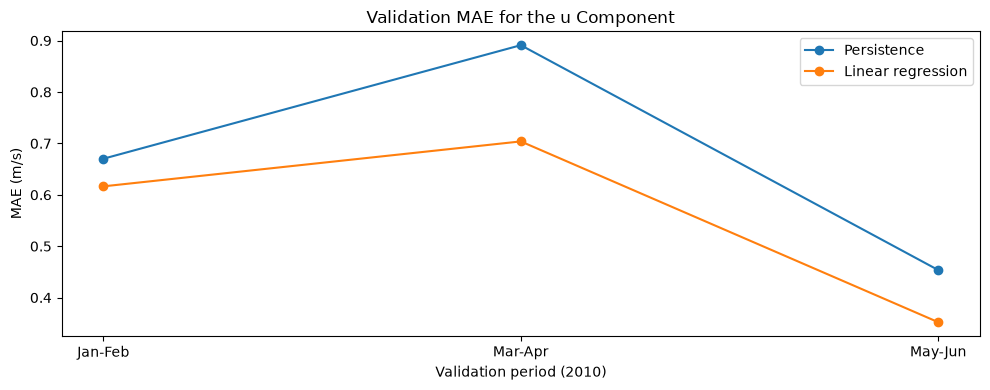

In [25]:
u_persistence_scores = wind_results[
    (wind_results["Component"] == "u") & (wind_results["Model"] == "Persistence")
]
u_linear_scores = wind_results[
    (wind_results["Component"] == "u") & (wind_results["Model"] == "Linear regression")
]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(u_persistence_scores["Period"], u_persistence_scores["MAE"], marker="o", label="Persistence")
ax.plot(u_linear_scores["Period"], u_linear_scores["MAE"], marker="o", label="Linear regression")
ax.set_xlabel("Validation period")
ax.set_ylabel("MAE (m/s)")
ax.set_title("Validation MAE for the u Component")
ax.legend()

ax.set_xticks([0, 1, 2], ["Jan-Feb", "Mar-Apr", "May-Jun"])
ax.set_xlabel("Validation period (2010)")
fig.tight_layout()

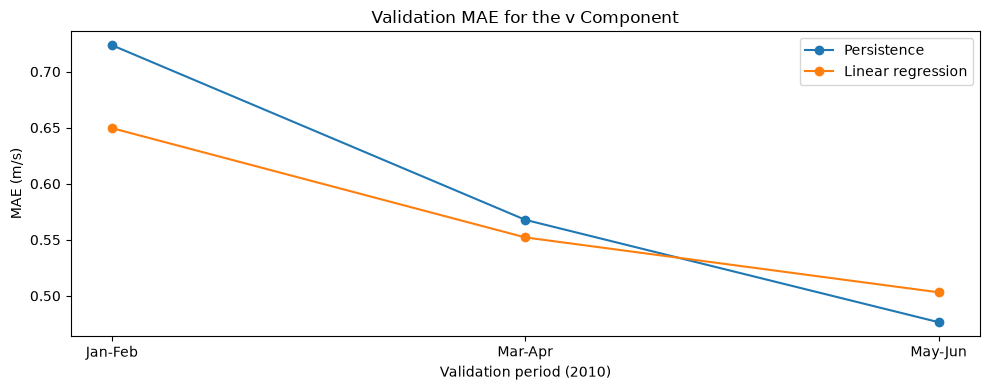

In [26]:
v_persistence_scores = wind_results[
    (wind_results["Component"] == "v") & (wind_results["Model"] == "Persistence")
]
v_linear_scores = wind_results[
    (wind_results["Component"] == "v") & (wind_results["Model"] == "Linear regression")
]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(v_persistence_scores["Period"], v_persistence_scores["MAE"], marker="o", label="Persistence")
ax.plot(v_linear_scores["Period"], v_linear_scores["MAE"], marker="o", label="Linear regression")
ax.set_xlabel("Validation period")
ax.set_ylabel("MAE (m/s)")
ax.set_title("Validation MAE for the v Component")
ax.legend()

ax.set_xticks([0, 1, 2], ["Jan-Feb", "Mar-Apr", "May-Jun"])
ax.set_xlabel("Validation period (2010)")
fig.tight_layout()

### Put all 181 validation days together

I join the daily errors and calculate MAE and RMSE across all 181 days, rather than averaging the three RMSE scores.

In [27]:
u_persistence_all = pd.concat([u_errors, u_persistence_errors_2, u_persistence_errors_3])
v_persistence_all = pd.concat([v_errors, v_persistence_errors_2, v_persistence_errors_3])
u_linear_all = pd.concat([u_linear_errors_1, u_linear_errors_2, u_linear_errors_3])
v_linear_all = pd.concat([v_linear_errors_1, v_linear_errors_2, v_linear_errors_3])

print("Validation days:", len(u_linear_all))
wind_summary = pd.DataFrame({
    "Component": ["u", "u", "v", "v"],
    "Model": ["Persistence", "Linear regression", "Persistence", "Linear regression"],
    "MAE": [
        u_persistence_all.abs().mean(), u_linear_all.abs().mean(),
        v_persistence_all.abs().mean(), v_linear_all.abs().mean()
    ],
    "RMSE": [
        ((u_persistence_all ** 2).mean()) ** 0.5,
        ((u_linear_all ** 2).mean()) ** 0.5,
        ((v_persistence_all ** 2).mean()) ** 0.5,
        ((v_linear_all ** 2).mean()) ** 0.5
    ]
})
wind_summary.round(4)

Validation days: 181


,Component,Model,MAE,RMSE
0,u,Persistence,0.6716,1.0142
1,u,Linear regression,0.5569,0.8183
2,v,Persistence,0.5878,0.7853
3,v,Linear regression,0.5674,0.7114


## 11. What I found so far

Linear regression lowers both errors for u in all three rounds. For v, RMSE improves each time, but MAE is a little worse in May-June.

Overall MAE goes from 0.6716 to 0.5569 m/s for u and from 0.5878 to 0.5674 m/s for v. Next I try adding recent wind averages.

## 12. Try 3-day and 7-day wind averages

Maybe the last few days of wind will help. I add 3-day and 7-day averages of u and v, using today and the days before it.

Because the values can be positive or negative, opposite wind directions can cancel in an average. I remove the first six rows because they do not have enough days for the 7-day average. I train both models on the same remaining rows.

In [28]:
df_wind_rolling = df_wind.copy()
df_wind_rolling["u_3day"] = df_wind_rolling["today_u"].rolling(3).mean()
df_wind_rolling["u_7day"] = df_wind_rolling["today_u"].rolling(7).mean()
df_wind_rolling["v_3day"] = df_wind_rolling["today_v"].rolling(3).mean()
df_wind_rolling["v_7day"] = df_wind_rolling["today_v"].rolling(7).mean()

rolling_features = ["today_u", "today_v", "u_3day", "u_7day", "v_3day", "v_7day"]
df_wind_rolling = df_wind_rolling.dropna(
    subset=rolling_features + ["tomorrow_u", "tomorrow_v"]
).copy()

print("Rows for modeling:", len(df_wind_rolling))
df_wind_rolling.head()

Rows for modeling: 723


,today_u,today_v,tomorrow_u,tomorrow_v,target_date,u_3day,u_7day,v_3day,v_7day
valid_time,,,,,,,,,
2009-01-07,-0.424782,0.109842,-0.259017,0.284220,2009-01-08,-0.609197,-0.657786,0.207735,0.318958
2009-01-08,-0.259017,0.284220,-0.780373,-0.067716,2009-01-09,-0.430038,-0.611753,0.342771,0.357727
2009-01-09,-0.780373,-0.067716,-1.647478,-1.601807,2009-01-10,-0.488057,-0.647190,0.108782,0.227609
2009-01-10,-1.647478,-1.601807,-1.519873,-1.268554,2009-01-11,-0.895622,-0.773097,-0.461768,-0.189405
2009-01-11,-1.519873,-1.268554,-2.062070,-1.226042,2009-01-12,-1.315908,-0.862047,-0.979359,-0.290093


### Look at the wind averages

I plot 2009 to check how the averages follow the daily values. The 7-day line is smoother, and opposite wind directions can cancel in an average.

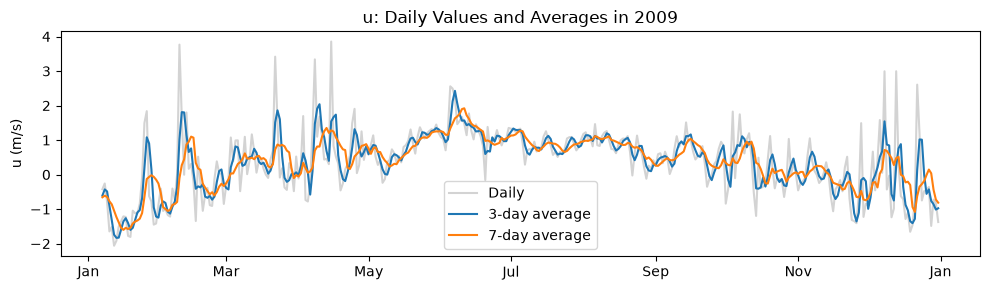

In [29]:
import matplotlib.dates as mdates

view = df_wind_rolling.loc["2009"]
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(view.index, view["today_u"], color="lightgray", label="Daily")
ax.plot(view.index, view["u_3day"], label="3-day average")
ax.plot(view.index, view["u_7day"], label="7-day average")
ax.set_ylabel("u (m/s)")
ax.set_title("u: Daily Values and Averages in 2009")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend()
fig.tight_layout()

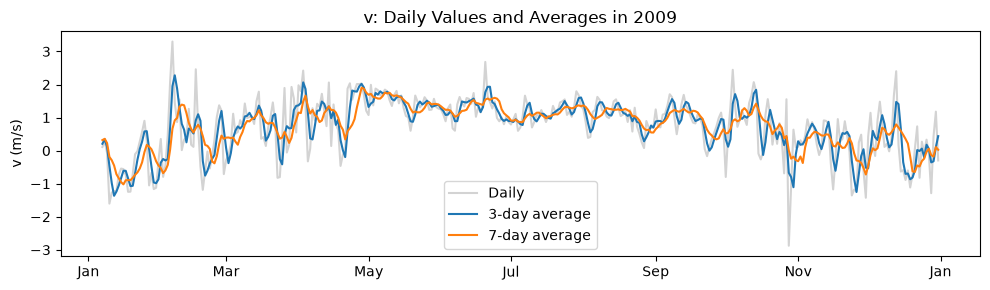

In [30]:
import matplotlib.dates as mdates

view = df_wind_rolling.loc["2009"]
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(view.index, view["today_v"], color="lightgray", label="Daily")
ax.plot(view.index, view["v_3day"], label="3-day average")
ax.plot(view.index, view["v_7day"], label="7-day average")
ax.set_ylabel("v (m/s)")
ax.set_title("v: Daily Values and Averages in 2009")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend()
fig.tight_layout()

### Round 1: January-February 2010

In [31]:
train_roll_1 = df_wind_rolling[df_wind_rolling["target_date"] < "2010-01-01"].copy()
val_roll_1 = df_wind_rolling[
    (df_wind_rolling["target_date"] >= "2010-01-01") &
    (df_wind_rolling["target_date"] < "2010-03-01")
].copy()

print("Training rows:", len(train_roll_1))
print("Validation rows:", len(val_roll_1))

Training rows: 358
Validation rows: 59


In [32]:
reg_u_today_1 = LinearRegression()
reg_u_today_1.fit(train_roll_1[wind_features], train_roll_1["tomorrow_u"])

reg_u_rolling_1 = LinearRegression()
reg_u_rolling_1.fit(train_roll_1[rolling_features], train_roll_1["tomorrow_u"])

reg_v_today_1 = LinearRegression()
reg_v_today_1.fit(train_roll_1[wind_features], train_roll_1["tomorrow_v"])

reg_v_rolling_1 = LinearRegression()
reg_v_rolling_1.fit(train_roll_1[rolling_features], train_roll_1["tomorrow_v"])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[-0.02, 0.58,-0.04, 0.28,-0.14, 0.16]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['today_u','today_v','u_3day','u_7day','v_3day','v_7day']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.2081
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


In [33]:
val_roll_1["u_today_pred"] = reg_u_today_1.predict(val_roll_1[wind_features])
u_today_error_1 = val_roll_1["u_today_pred"] - val_roll_1["tomorrow_u"]

val_roll_1["u_rolling_pred"] = reg_u_rolling_1.predict(val_roll_1[rolling_features])
u_rolling_error_1 = val_roll_1["u_rolling_pred"] - val_roll_1["tomorrow_u"]

val_roll_1["v_today_pred"] = reg_v_today_1.predict(val_roll_1[wind_features])
v_today_error_1 = val_roll_1["v_today_pred"] - val_roll_1["tomorrow_v"]

val_roll_1["v_rolling_pred"] = reg_v_rolling_1.predict(val_roll_1[rolling_features])
v_rolling_error_1 = val_roll_1["v_rolling_pred"] - val_roll_1["tomorrow_v"]

In [34]:
rolling_results_1 = pd.DataFrame({
    "Period": "January-February 2010",
    "Component": ["u", "u", "v", "v"],
    "Model": ["Today-only", "With averages", "Today-only", "With averages"],
    "MAE": [
        u_today_error_1.abs().mean(),
        u_rolling_error_1.abs().mean(),
        v_today_error_1.abs().mean(),
        v_rolling_error_1.abs().mean()
    ],
    "RMSE": [
        ((u_today_error_1 ** 2).mean()) ** 0.5,
        ((u_rolling_error_1 ** 2).mean()) ** 0.5,
        ((v_today_error_1 ** 2).mean()) ** 0.5,
        ((v_rolling_error_1 ** 2).mean()) ** 0.5
    ]
})
rolling_results_1.round(4)

,Period,Component,Model,MAE,RMSE
0,January-February 2010,u,Today-only,0.6195,0.8454
1,January-February 2010,u,With averages,0.5894,0.8077
2,January-February 2010,v,Today-only,0.6500,0.8347
3,January-February 2010,v,With averages,0.6156,0.8091


### Round 2: March-April 2010

In [35]:
train_roll_2 = df_wind_rolling[df_wind_rolling["target_date"] < "2010-03-01"].copy()
val_roll_2 = df_wind_rolling[
    (df_wind_rolling["target_date"] >= "2010-03-01") &
    (df_wind_rolling["target_date"] < "2010-05-01")
].copy()

print("Training rows:", len(train_roll_2))
print("Validation rows:", len(val_roll_2))

Training rows: 417
Validation rows: 61


In [36]:
reg_u_today_2 = LinearRegression()
reg_u_today_2.fit(train_roll_2[wind_features], train_roll_2["tomorrow_u"])

reg_u_rolling_2 = LinearRegression()
reg_u_rolling_2.fit(train_roll_2[rolling_features], train_roll_2["tomorrow_u"])

reg_v_today_2 = LinearRegression()
reg_v_today_2.fit(train_roll_2[wind_features], train_roll_2["tomorrow_v"])

reg_v_rolling_2 = LinearRegression()
reg_v_rolling_2.fit(train_roll_2[rolling_features], train_roll_2["tomorrow_v"])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[-0.03, 0.54,-0.11, 0.36,-0.05, 0.09]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['today_u','today_v','u_3day','u_7day','v_3day','v_7day']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.2274
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


In [37]:
val_roll_2["u_today_pred"] = reg_u_today_2.predict(val_roll_2[wind_features])
u_today_error_2 = val_roll_2["u_today_pred"] - val_roll_2["tomorrow_u"]

val_roll_2["u_rolling_pred"] = reg_u_rolling_2.predict(val_roll_2[rolling_features])
u_rolling_error_2 = val_roll_2["u_rolling_pred"] - val_roll_2["tomorrow_u"]

val_roll_2["v_today_pred"] = reg_v_today_2.predict(val_roll_2[wind_features])
v_today_error_2 = val_roll_2["v_today_pred"] - val_roll_2["tomorrow_v"]

val_roll_2["v_rolling_pred"] = reg_v_rolling_2.predict(val_roll_2[rolling_features])
v_rolling_error_2 = val_roll_2["v_rolling_pred"] - val_roll_2["tomorrow_v"]

In [38]:
rolling_results_2 = pd.DataFrame({
    "Period": "March-April 2010",
    "Component": ["u", "u", "v", "v"],
    "Model": ["Today-only", "With averages", "Today-only", "With averages"],
    "MAE": [
        u_today_error_2.abs().mean(),
        u_rolling_error_2.abs().mean(),
        v_today_error_2.abs().mean(),
        v_rolling_error_2.abs().mean()
    ],
    "RMSE": [
        ((u_today_error_2 ** 2).mean()) ** 0.5,
        ((u_rolling_error_2 ** 2).mean()) ** 0.5,
        ((v_today_error_2 ** 2).mean()) ** 0.5,
        ((v_rolling_error_2 ** 2).mean()) ** 0.5
    ]
})
rolling_results_2.round(4)

,Period,Component,Model,MAE,RMSE
0,March-April 2010,u,Today-only,0.7032,1.0171
1,March-April 2010,u,With averages,0.7205,1.0284
2,March-April 2010,v,Today-only,0.5505,0.6888
3,March-April 2010,v,With averages,0.5477,0.6853


### Round 3: May-June 2010

In [39]:
train_roll_3 = df_wind_rolling[df_wind_rolling["target_date"] < "2010-05-01"].copy()
val_roll_3 = df_wind_rolling[
    (df_wind_rolling["target_date"] >= "2010-05-01") &
    (df_wind_rolling["target_date"] < "2010-07-01")
].copy()

print("Training rows:", len(train_roll_3))
print("Validation rows:", len(val_roll_3))

Training rows: 478
Validation rows: 61


In [40]:
reg_u_today_3 = LinearRegression()
reg_u_today_3.fit(train_roll_3[wind_features], train_roll_3["tomorrow_u"])

reg_u_rolling_3 = LinearRegression()
reg_u_rolling_3.fit(train_roll_3[rolling_features], train_roll_3["tomorrow_u"])

reg_v_today_3 = LinearRegression()
reg_v_today_3.fit(train_roll_3[wind_features], train_roll_3["tomorrow_v"])

reg_v_rolling_3 = LinearRegression()
reg_v_rolling_3.fit(train_roll_3[rolling_features], train_roll_3["tomorrow_v"])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[-0.04, 0.59,-0.06, 0.28,-0.18, 0.19]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['today_u','today_v','u_3day','u_7day','v_3day','v_7day']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.2223
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


In [41]:
val_roll_3["u_today_pred"] = reg_u_today_3.predict(val_roll_3[wind_features])
u_today_error_3 = val_roll_3["u_today_pred"] - val_roll_3["tomorrow_u"]

val_roll_3["u_rolling_pred"] = reg_u_rolling_3.predict(val_roll_3[rolling_features])
u_rolling_error_3 = val_roll_3["u_rolling_pred"] - val_roll_3["tomorrow_u"]

val_roll_3["v_today_pred"] = reg_v_today_3.predict(val_roll_3[wind_features])
v_today_error_3 = val_roll_3["v_today_pred"] - val_roll_3["tomorrow_v"]

val_roll_3["v_rolling_pred"] = reg_v_rolling_3.predict(val_roll_3[rolling_features])
v_rolling_error_3 = val_roll_3["v_rolling_pred"] - val_roll_3["tomorrow_v"]

In [42]:
rolling_results_3 = pd.DataFrame({
    "Period": "May-June 2010",
    "Component": ["u", "u", "v", "v"],
    "Model": ["Today-only", "With averages", "Today-only", "With averages"],
    "MAE": [
        u_today_error_3.abs().mean(),
        u_rolling_error_3.abs().mean(),
        v_today_error_3.abs().mean(),
        v_rolling_error_3.abs().mean()
    ],
    "RMSE": [
        ((u_today_error_3 ** 2).mean()) ** 0.5,
        ((u_rolling_error_3 ** 2).mean()) ** 0.5,
        ((v_today_error_3 ** 2).mean()) ** 0.5,
        ((v_rolling_error_3 ** 2).mean()) ** 0.5
    ]
})
rolling_results_3.round(4)

,Period,Component,Model,MAE,RMSE
0,May-June 2010,u,Today-only,0.3544,0.5118
1,May-June 2010,u,With averages,0.3796,0.5336
2,May-June 2010,v,Today-only,0.5019,0.5930
3,May-June 2010,v,With averages,0.4655,0.5461


## 13. Compare the results

I check whether the averages helped u and v in each round. Then I put all 181 daily errors together to calculate the overall MAE and RMSE.

In [43]:
rolling_results = pd.concat(
    [rolling_results_1, rolling_results_2, rolling_results_3], ignore_index=True
)
rolling_results.round(4)

,Period,Component,Model,MAE,RMSE
0,January-February 2010,u,Today-only,0.6195,0.8454
1,January-February 2010,u,With averages,0.5894,0.8077
2,January-February 2010,v,Today-only,0.6500,0.8347
3,January-February 2010,v,With averages,0.6156,0.8091
4,March-April 2010,u,Today-only,0.7032,1.0171
5,March-April 2010,u,With averages,0.7205,1.0284
6,March-April 2010,v,Today-only,0.5505,0.6888
7,March-April 2010,v,With averages,0.5477,0.6853
8,May-June 2010,u,Today-only,0.3544,0.5118
9,May-June 2010,u,With averages,0.3796,0.5336


In [44]:
u_today_all = pd.concat([u_today_error_1, u_today_error_2, u_today_error_3])
u_rolling_all = pd.concat([u_rolling_error_1, u_rolling_error_2, u_rolling_error_3])
v_today_all = pd.concat([v_today_error_1, v_today_error_2, v_today_error_3])
v_rolling_all = pd.concat([v_rolling_error_1, v_rolling_error_2, v_rolling_error_3])

rolling_summary = pd.DataFrame({
    "Component": ["u", "u", "v", "v"],
    "Model": ["Today-only", "With averages", "Today-only", "With averages"],
    "MAE": [
        u_today_all.abs().mean(),
        u_rolling_all.abs().mean(),
        v_today_all.abs().mean(),
        v_rolling_all.abs().mean()
    ],
    "RMSE": [
        ((u_today_all ** 2).mean()) ** 0.5,
        ((u_rolling_all ** 2).mean()) ** 0.5,
        ((v_today_all ** 2).mean()) ** 0.5,
        ((v_rolling_all ** 2).mean()) ** 0.5
    ]
})
rolling_summary.round(4)

,Component,Model,MAE,RMSE
0,u,Today-only,0.5584,0.8185
1,u,With averages,0.5629,0.8155
2,v,Today-only,0.5666,0.7110
3,v,With averages,0.5421,0.6871


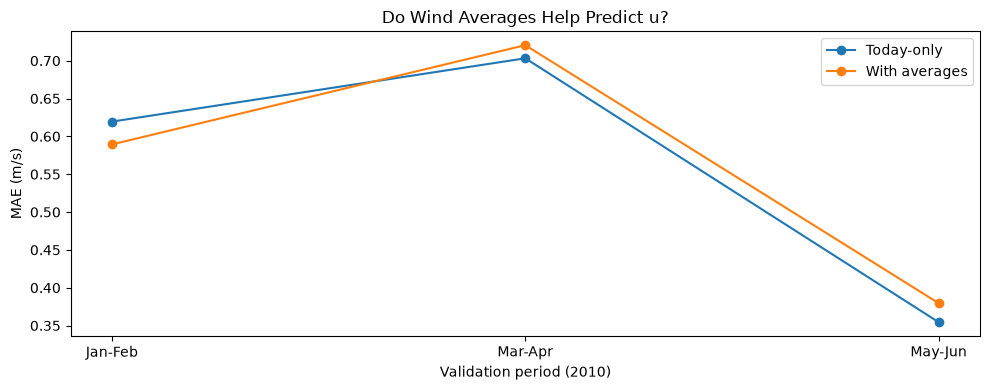

In [45]:
u_today_scores = rolling_results[
    (rolling_results["Component"] == "u") & (rolling_results["Model"] == "Today-only")
]
u_rolling_scores = rolling_results[
    (rolling_results["Component"] == "u") & (rolling_results["Model"] == "With averages")
]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(u_today_scores["Period"], u_today_scores["MAE"], marker="o", label="Today-only")
ax.plot(u_rolling_scores["Period"], u_rolling_scores["MAE"], marker="o", label="With averages")
ax.set_xlabel("Validation period")
ax.set_ylabel("MAE (m/s)")
ax.set_title("Do Wind Averages Help Predict u?")
ax.legend()

ax.set_xticks([0, 1, 2], ["Jan-Feb", "Mar-Apr", "May-Jun"])
ax.set_xlabel("Validation period (2010)")
fig.tight_layout()

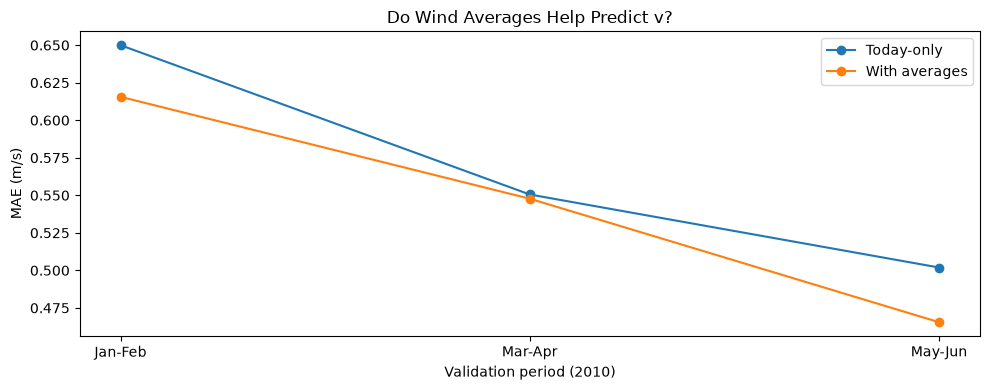

In [46]:
v_today_scores = rolling_results[
    (rolling_results["Component"] == "v") & (rolling_results["Model"] == "Today-only")
]
v_rolling_scores = rolling_results[
    (rolling_results["Component"] == "v") & (rolling_results["Model"] == "With averages")
]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(v_today_scores["Period"], v_today_scores["MAE"], marker="o", label="Today-only")
ax.plot(v_rolling_scores["Period"], v_rolling_scores["MAE"], marker="o", label="With averages")
ax.set_xlabel("Validation period")
ax.set_ylabel("MAE (m/s)")
ax.set_title("Do Wind Averages Help Predict v?")
ax.legend()

ax.set_xticks([0, 1, 2], ["Jan-Feb", "Mar-Apr", "May-Jun"])
ax.set_xlabel("Validation period (2010)")
fig.tight_layout()

## 14. Do the averages help?

The averages help v in all three rounds. Overall MAE drops from 0.5666 to 0.5421 m/s, and RMSE from 0.7110 to 0.6871 m/s.

For u, they only help both scores in the first round. Overall MAE is slightly worse and RMSE slightly better. I keep today's u and v for predicting u, and add the averages for predicting v.

The today-only scores are a little different from before because I removed the first six training rows for this comparison. Next I try adding pressure.

## 15. Does pressure help predict wind?

I add today's pressure to both models. The u model uses today's u and v; the v model also uses the wind averages. I compare them on the same rows and dates.

In [47]:
pressure_files = sorted(glob.glob(f"{DATA_DIR}/**/mean_sea_level_pressure*.nc", recursive=True))
ds_pressure = xr.open_mfdataset(pressure_files, combine="by_coords")
pressure_irvine = ds_pressure["msl"].sel(latitude=33.75, longitude=-117.75, method="nearest")

print("Pressure files:", len(pressure_files))
print("Pressure units:", pressure_irvine.attrs.get("units"))
print("Location:", float(pressure_irvine.latitude), float(pressure_irvine.longitude))

Pressure files: 12
Pressure units: Pa
Location: 33.75 -117.75


In [48]:
# Change pressure from Pa to hPa, as in notebook 03.
pressure_series = (pressure_irvine / 100).to_series()
print("Same dates:", pressure_series.index.equals(df_wind.index))
print("Missing pressure values:", pressure_series.isna().sum())

df_wind_pressure = df_wind_rolling.copy()
df_wind_pressure["pressure_hpa"] = pressure_series
df_wind_pressure = df_wind_pressure.dropna(subset=["pressure_hpa"]).copy()
print("Same modeling rows:", df_wind_pressure.index.equals(df_wind_rolling.index))

u_base_features = wind_features
v_base_features = rolling_features
u_pressure_features = u_base_features + ["pressure_hpa"]
v_pressure_features = v_base_features + ["pressure_hpa"]
df_wind_pressure.head()

Same dates: True
Missing pressure values: 0
Same modeling rows: True


,today_u,today_v,tomorrow_u,tomorrow_v,target_date,u_3day,u_7day,v_3day,v_7day,pressure_hpa
valid_time,,,,,,,,,,
2009-01-07,-0.424782,0.109842,-0.259017,0.284220,2009-01-08,-0.609197,-0.657786,0.207735,0.318958,1021.168518
2009-01-08,-0.259017,0.284220,-0.780373,-0.067716,2009-01-09,-0.430038,-0.611753,0.342771,0.357727,1017.560364
2009-01-09,-0.780373,-0.067716,-1.647478,-1.601807,2009-01-10,-0.488057,-0.647190,0.108782,0.227609,1017.018799
2009-01-10,-1.647478,-1.601807,-1.519873,-1.268554,2009-01-11,-0.895622,-0.773097,-0.461768,-0.189405,1025.754639
2009-01-11,-1.519873,-1.268554,-2.062070,-1.226042,2009-01-12,-1.315908,-0.862047,-0.979359,-0.290093,1026.206543


### Round 1: Jan-Feb 2010

In [49]:
train_pressure_1 = df_wind_pressure[df_wind_pressure["target_date"] < "2010-01-01"].copy()
val_pressure_1 = df_wind_pressure[
    (df_wind_pressure["target_date"] >= "2010-01-01") &
    (df_wind_pressure["target_date"] < "2010-03-01")
].copy()

print("Training rows:", len(train_pressure_1))
print("Validation rows:", len(val_pressure_1))

Training rows: 358
Validation rows: 59


In [50]:
reg_u_base_p1 = LinearRegression()
reg_u_base_p1.fit(train_pressure_1[u_base_features], train_pressure_1["tomorrow_u"])

reg_u_pressure_p1 = LinearRegression()
reg_u_pressure_p1.fit(train_pressure_1[u_pressure_features], train_pressure_1["tomorrow_u"])

reg_v_base_p1 = LinearRegression()
reg_v_base_p1.fit(train_pressure_1[v_base_features], train_pressure_1["tomorrow_v"])

reg_v_pressure_p1 = LinearRegression()
reg_v_pressure_p1.fit(train_pressure_1[v_pressure_features], train_pressure_1["tomorrow_v"])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[-0.04, 0.56,-0.01,...,-0.15, 0.15,-0.03]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['today_u','today_v','u_3day',...,'v_3day','v_7day','pressure_hpa']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,25.8
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [51]:
val_pressure_1["u_base_pred"] = reg_u_base_p1.predict(val_pressure_1[u_base_features])
u_base_error_p1 = val_pressure_1["u_base_pred"] - val_pressure_1["tomorrow_u"]

val_pressure_1["u_pressure_pred"] = reg_u_pressure_p1.predict(val_pressure_1[u_pressure_features])
u_pressure_error_p1 = val_pressure_1["u_pressure_pred"] - val_pressure_1["tomorrow_u"]

val_pressure_1["v_base_pred"] = reg_v_base_p1.predict(val_pressure_1[v_base_features])
v_base_error_p1 = val_pressure_1["v_base_pred"] - val_pressure_1["tomorrow_v"]

val_pressure_1["v_pressure_pred"] = reg_v_pressure_p1.predict(val_pressure_1[v_pressure_features])
v_pressure_error_p1 = val_pressure_1["v_pressure_pred"] - val_pressure_1["tomorrow_v"]

In [52]:
pressure_results_1 = pd.DataFrame({
    "Period": "Jan-Feb 2010",
    "Component": ["u", "u", "v", "v"],
    "Model": ["Without pressure", "With pressure", "Without pressure", "With pressure"],
    "MAE": [
        u_base_error_p1.abs().mean(),
        u_pressure_error_p1.abs().mean(),
        v_base_error_p1.abs().mean(),
        v_pressure_error_p1.abs().mean()
    ],
    "RMSE": [
        ((u_base_error_p1 ** 2).mean()) ** 0.5,
        ((u_pressure_error_p1 ** 2).mean()) ** 0.5,
        ((v_base_error_p1 ** 2).mean()) ** 0.5,
        ((v_pressure_error_p1 ** 2).mean()) ** 0.5
    ]
})
pressure_results_1.round(4)

,Period,Component,Model,MAE,RMSE
0,Jan-Feb 2010,u,Without pressure,0.6195,0.8454
1,Jan-Feb 2010,u,With pressure,0.6255,0.8485
2,Jan-Feb 2010,v,Without pressure,0.6156,0.8091
3,Jan-Feb 2010,v,With pressure,0.5999,0.7910


### Round 2: Mar-Apr 2010

In [53]:
train_pressure_2 = df_wind_pressure[df_wind_pressure["target_date"] < "2010-03-01"].copy()
val_pressure_2 = df_wind_pressure[
    (df_wind_pressure["target_date"] >= "2010-03-01") &
    (df_wind_pressure["target_date"] < "2010-05-01")
].copy()

print("Training rows:", len(train_pressure_2))
print("Validation rows:", len(val_pressure_2))

Training rows: 417
Validation rows: 61


In [54]:
reg_u_base_p2 = LinearRegression()
reg_u_base_p2.fit(train_pressure_2[u_base_features], train_pressure_2["tomorrow_u"])

reg_u_pressure_p2 = LinearRegression()
reg_u_pressure_p2.fit(train_pressure_2[u_pressure_features], train_pressure_2["tomorrow_u"])

reg_v_base_p2 = LinearRegression()
reg_v_base_p2.fit(train_pressure_2[v_base_features], train_pressure_2["tomorrow_v"])

reg_v_pressure_p2 = LinearRegression()
reg_v_pressure_p2.fit(train_pressure_2[v_pressure_features], train_pressure_2["tomorrow_v"])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[-0.06, 0.51,-0.06,...,-0.07, 0.06,-0.03]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['today_u','today_v','u_3day',...,'v_3day','v_7day','pressure_hpa']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,30.4
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [55]:
val_pressure_2["u_base_pred"] = reg_u_base_p2.predict(val_pressure_2[u_base_features])
u_base_error_p2 = val_pressure_2["u_base_pred"] - val_pressure_2["tomorrow_u"]

val_pressure_2["u_pressure_pred"] = reg_u_pressure_p2.predict(val_pressure_2[u_pressure_features])
u_pressure_error_p2 = val_pressure_2["u_pressure_pred"] - val_pressure_2["tomorrow_u"]

val_pressure_2["v_base_pred"] = reg_v_base_p2.predict(val_pressure_2[v_base_features])
v_base_error_p2 = val_pressure_2["v_base_pred"] - val_pressure_2["tomorrow_v"]

val_pressure_2["v_pressure_pred"] = reg_v_pressure_p2.predict(val_pressure_2[v_pressure_features])
v_pressure_error_p2 = val_pressure_2["v_pressure_pred"] - val_pressure_2["tomorrow_v"]

In [56]:
pressure_results_2 = pd.DataFrame({
    "Period": "Mar-Apr 2010",
    "Component": ["u", "u", "v", "v"],
    "Model": ["Without pressure", "With pressure", "Without pressure", "With pressure"],
    "MAE": [
        u_base_error_p2.abs().mean(),
        u_pressure_error_p2.abs().mean(),
        v_base_error_p2.abs().mean(),
        v_pressure_error_p2.abs().mean()
    ],
    "RMSE": [
        ((u_base_error_p2 ** 2).mean()) ** 0.5,
        ((u_pressure_error_p2 ** 2).mean()) ** 0.5,
        ((v_base_error_p2 ** 2).mean()) ** 0.5,
        ((v_pressure_error_p2 ** 2).mean()) ** 0.5
    ]
})
pressure_results_2.round(4)

,Period,Component,Model,MAE,RMSE
0,Mar-Apr 2010,u,Without pressure,0.7032,1.0171
1,Mar-Apr 2010,u,With pressure,0.7136,1.0260
2,Mar-Apr 2010,v,Without pressure,0.5477,0.6853
3,Mar-Apr 2010,v,With pressure,0.5330,0.6677


### Round 3: May-Jun 2010

In [57]:
train_pressure_3 = df_wind_pressure[df_wind_pressure["target_date"] < "2010-05-01"].copy()
val_pressure_3 = df_wind_pressure[
    (df_wind_pressure["target_date"] >= "2010-05-01") &
    (df_wind_pressure["target_date"] < "2010-07-01")
].copy()

print("Training rows:", len(train_pressure_3))
print("Validation rows:", len(val_pressure_3))

Training rows: 478
Validation rows: 61


In [58]:
reg_u_base_p3 = LinearRegression()
reg_u_base_p3.fit(train_pressure_3[u_base_features], train_pressure_3["tomorrow_u"])

reg_u_pressure_p3 = LinearRegression()
reg_u_pressure_p3.fit(train_pressure_3[u_pressure_features], train_pressure_3["tomorrow_u"])

reg_v_base_p3 = LinearRegression()
reg_v_base_p3.fit(train_pressure_3[v_base_features], train_pressure_3["tomorrow_v"])

reg_v_pressure_p3 = LinearRegression()
reg_v_pressure_p3.fit(train_pressure_3[v_pressure_features], train_pressure_3["tomorrow_v"])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[-0.07, 0.55,-0.02,...,-0.18, 0.16,-0.03]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['today_u','today_v','u_3day',...,'v_3day','v_7day','pressure_hpa']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,33.54
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [59]:
val_pressure_3["u_base_pred"] = reg_u_base_p3.predict(val_pressure_3[u_base_features])
u_base_error_p3 = val_pressure_3["u_base_pred"] - val_pressure_3["tomorrow_u"]

val_pressure_3["u_pressure_pred"] = reg_u_pressure_p3.predict(val_pressure_3[u_pressure_features])
u_pressure_error_p3 = val_pressure_3["u_pressure_pred"] - val_pressure_3["tomorrow_u"]

val_pressure_3["v_base_pred"] = reg_v_base_p3.predict(val_pressure_3[v_base_features])
v_base_error_p3 = val_pressure_3["v_base_pred"] - val_pressure_3["tomorrow_v"]

val_pressure_3["v_pressure_pred"] = reg_v_pressure_p3.predict(val_pressure_3[v_pressure_features])
v_pressure_error_p3 = val_pressure_3["v_pressure_pred"] - val_pressure_3["tomorrow_v"]

In [60]:
pressure_results_3 = pd.DataFrame({
    "Period": "May-Jun 2010",
    "Component": ["u", "u", "v", "v"],
    "Model": ["Without pressure", "With pressure", "Without pressure", "With pressure"],
    "MAE": [
        u_base_error_p3.abs().mean(),
        u_pressure_error_p3.abs().mean(),
        v_base_error_p3.abs().mean(),
        v_pressure_error_p3.abs().mean()
    ],
    "RMSE": [
        ((u_base_error_p3 ** 2).mean()) ** 0.5,
        ((u_pressure_error_p3 ** 2).mean()) ** 0.5,
        ((v_base_error_p3 ** 2).mean()) ** 0.5,
        ((v_pressure_error_p3 ** 2).mean()) ** 0.5
    ]
})
pressure_results_3.round(4)

,Period,Component,Model,MAE,RMSE
0,May-Jun 2010,u,Without pressure,0.3544,0.5118
1,May-Jun 2010,u,With pressure,0.3562,0.5178
2,May-Jun 2010,v,Without pressure,0.4655,0.5461
3,May-Jun 2010,v,With pressure,0.4601,0.5429


## 16. Compare pressure results

I compare each component with and without pressure. For the overall scores, I join the errors from all three rounds first.

In [61]:
pressure_results = pd.concat(
    [pressure_results_1, pressure_results_2, pressure_results_3], ignore_index=True
)
pressure_results.round(4)

,Period,Component,Model,MAE,RMSE
0,Jan-Feb 2010,u,Without pressure,0.6195,0.8454
1,Jan-Feb 2010,u,With pressure,0.6255,0.8485
2,Jan-Feb 2010,v,Without pressure,0.6156,0.8091
3,Jan-Feb 2010,v,With pressure,0.5999,0.7910
4,Mar-Apr 2010,u,Without pressure,0.7032,1.0171
5,Mar-Apr 2010,u,With pressure,0.7136,1.0260
6,Mar-Apr 2010,v,Without pressure,0.5477,0.6853
7,Mar-Apr 2010,v,With pressure,0.5330,0.6677
8,May-Jun 2010,u,Without pressure,0.3544,0.5118
9,May-Jun 2010,u,With pressure,0.3562,0.5178


In [62]:
u_base_all_p = pd.concat([u_base_error_p1, u_base_error_p2, u_base_error_p3])
u_pressure_all_p = pd.concat([u_pressure_error_p1, u_pressure_error_p2, u_pressure_error_p3])
v_base_all_p = pd.concat([v_base_error_p1, v_base_error_p2, v_base_error_p3])
v_pressure_all_p = pd.concat([v_pressure_error_p1, v_pressure_error_p2, v_pressure_error_p3])

print("Validation days:", len(u_pressure_all_p))
pressure_summary = pd.DataFrame({
    "Component": ["u", "u", "v", "v"],
    "Model": ["Without pressure", "With pressure", "Without pressure", "With pressure"],
    "MAE": [
        u_base_all_p.abs().mean(),
        u_pressure_all_p.abs().mean(),
        v_base_all_p.abs().mean(),
        v_pressure_all_p.abs().mean()
    ],
    "RMSE": [
        ((u_base_all_p ** 2).mean()) ** 0.5,
        ((u_pressure_all_p ** 2).mean()) ** 0.5,
        ((v_base_all_p ** 2).mean()) ** 0.5,
        ((v_pressure_all_p ** 2).mean()) ** 0.5
    ]
})
pressure_summary.round(4)

Validation days: 181


,Component,Model,MAE,RMSE
0,u,Without pressure,0.5584,0.8185
1,u,With pressure,0.5644,0.8245
2,v,Without pressure,0.5421,0.6871
3,v,With pressure,0.5302,0.6735


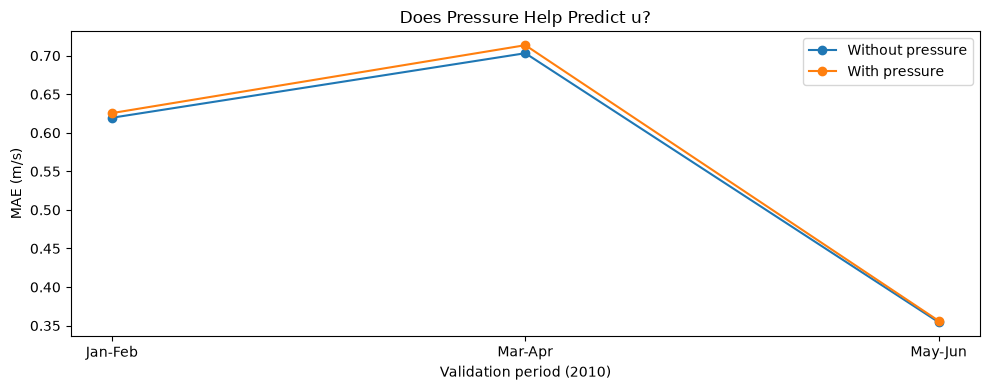

In [63]:
u_without_pressure = pressure_results[
    (pressure_results["Component"] == "u") & (pressure_results["Model"] == "Without pressure")
]
u_with_pressure = pressure_results[
    (pressure_results["Component"] == "u") & (pressure_results["Model"] == "With pressure")
]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(u_without_pressure["Period"], u_without_pressure["MAE"], marker="o", label="Without pressure")
ax.plot(u_with_pressure["Period"], u_with_pressure["MAE"], marker="o", label="With pressure")
ax.set_xlabel("Validation period")
ax.set_ylabel("MAE (m/s)")
ax.set_title("Does Pressure Help Predict u?")
ax.legend()

ax.set_xticks([0, 1, 2], ["Jan-Feb", "Mar-Apr", "May-Jun"])
ax.set_xlabel("Validation period (2010)")
fig.tight_layout()

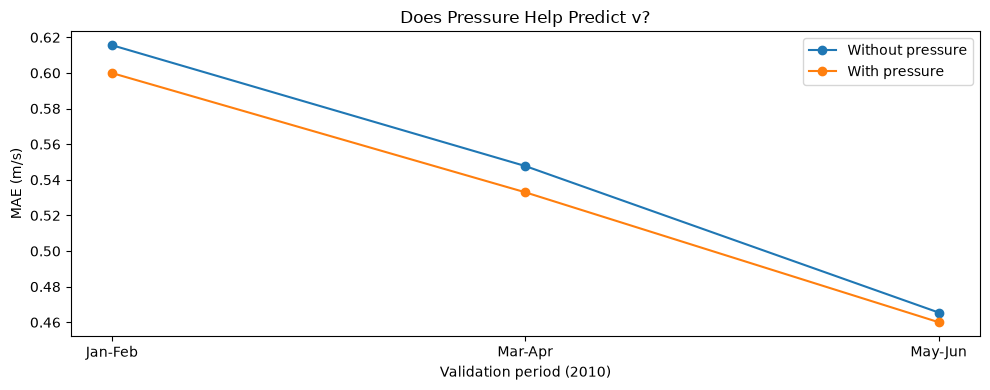

In [64]:
v_without_pressure = pressure_results[
    (pressure_results["Component"] == "v") & (pressure_results["Model"] == "Without pressure")
]
v_with_pressure = pressure_results[
    (pressure_results["Component"] == "v") & (pressure_results["Model"] == "With pressure")
]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(v_without_pressure["Period"], v_without_pressure["MAE"], marker="o", label="Without pressure")
ax.plot(v_with_pressure["Period"], v_with_pressure["MAE"], marker="o", label="With pressure")
ax.set_xlabel("Validation period")
ax.set_ylabel("MAE (m/s)")
ax.set_title("Does Pressure Help Predict v?")
ax.legend()

ax.set_xticks([0, 1, 2], ["Jan-Feb", "Mar-Apr", "May-Jun"])
ax.set_xlabel("Validation period (2010)")
fig.tight_layout()

## 17. What I found after adding pressure

Pressure makes the u predictions slightly worse in all three rounds, but helps v a little each time. For v, MAE drops from 0.5421 to 0.5302 m/s and RMSE from 0.6871 to 0.6735 m/s.

Based on these comparisons, I keep:

- For tomorrow's u: today's u and v.
- For tomorrow's v: today's u and v, their 3-day and 7-day averages, and today's pressure.

Notebook 06 checks these choices on July-December. Next I work on precipitation in notebook 05.